In [1]:
import os
import cv2
import pyewts
import fastwer
import numpy as np
from glob import glob
from tqdm import tqdm
from natsort import natsorted
from Utils import read_label, get_file_name, pad_image, pad_image2, binarize_line, process_wylie_label
from Modules import OnnxInference
from evaluate import load

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def resize_to_height(image, target_height: int):
    width_ratio = target_height / image.shape[0]
    image = cv2.resize(image, (int(image.shape[1] * width_ratio), target_height))
    return image


def prepare_ocr_image2(
    line_image: np.array, target_width: int = 2000, target_height: int = 80
    ):

        if len(line_image.shape) > 2:
            line_image = cv2.cvtColor(line_image, cv2.COLOR_BGR2GRAY)

        image = pad_image2(
            line_image,
            target_width=target_width,
            target_height=target_height,
            padding="black",
        )
        
        image = image.reshape((1, target_height, target_width))

        #image = (image / 127.5) - 1.0
        image = image / 255.0
        image = image.astype(np.float32)
        return image

In [3]:
converter = pyewts.pyewts()
cer_scorer = load("cer")

In [12]:
#dataset_root = "Models/OCRModels"
#dataset = "DergeTenjur"
#chckpt = "2024_1_25_6_48"


"""dataset_root = "Models/OCRModels"
dataset = "LhasaKanjur"
chckpt = "Prodigy_2023_9_13_7_59"

model_config = f"{dataset_root}/{dataset}/{chckpt}/model_config.json"
ocr_inference = OnnxInference(config_file=model_config)
"""

"""
dataset_root = "Models/OCRModels"
dataset = "LhasaKanjurEaster"
chckpt = "model_config"
"""
"""
dataset_root = "Models/OCRModels"
dataset = "LithangKanjur"
chckpt = "2023_12_11_19_46"
"""
dataset_root = "Models/OCRModels"
dataset = "DergeTenjur"
chckpt = "2024_1_30_9_38"

model_config = f"{dataset_root}/{dataset}/{chckpt}/model_config.json"
#ocr_model_config = f"{models_path}/{dataset}/model_config.json"

#ocr_model_config = "Models/OCRModels/DergeTenjur/November2023_v2/model_config.json"
ocr_inference = OnnxInference(config_file=model_config, mode="cuda")

In [5]:
test_set_index = f"{dataset_root}/{dataset}/{chckpt}/test_imgs.txt"

with open(test_set_index, "r") as f:
    entries = f.readlines()
    entries = [get_file_name(x) for x in entries]

print(entries[:10])
print(len(entries))

['87-1-258a_6', '89-1-117b_0', '13370370_6', '44-1-46a_1', '13380061_4', '77-1-105b_7', '48-1-319a_3', '25-1-105a_0', '16-1-122a_0', '87-1-323a_7']
60160


In [11]:
#dataset_path = "Data/W23703/Dataset"
#dataset_path = "D:/Datasets/Tibetan/LhasaKanjur/LhasaKanjurProdigy_v1_reviewed"
dataset_path = "D:/Datasets/Tibetan/OCR/LithangKanjur/DatasetFiltered"
#dataset_path = "D:/Datasets/Tibetan/Glomanthang/Glomanthang_January204_merged_bw"
all_images = natsorted(glob(f"{dataset_path}/lines/*.jpg"))
all_labels = natsorted(glob(f"{dataset_path}/transcriptions/*.txt"))

print(f"All Images: {len(all_images)}, All Labels: {len(all_images)}")

test_images = [f"{dataset_path}/lines/{x}.jpg" for x in entries]
test_labels = [f"{dataset_path}/transcriptions/{x}.txt" for x in entries]

print(f"Test Images: {len(test_images)}, Test Labels: {len(test_labels)}")

All Images: 520000, All Labels: 520000
Test Images: 60160, Test Labels: 60160


In [10]:
def preprocess_wylie(label: str) -> str:
    label = label.replace("/ /", "//")
    label = label.replace("/_/", "//")
    label = label.replace("/ ", "/")
    label = label.replace("/_", "/")
    return label

In [ ]:
cer_scores = []

for image, label in tqdm(zip(test_images, test_labels), total=len(test_images)):
    test_img = cv2.imread(image)
    test_lbl = read_label(label)
    #test_lbl = converter.toWylie(test_lbl)
    test_lbl = preprocess_wylie(test_lbl)
    test_lbl = process_wylie_label(test_lbl)

    test_img = prepare_ocr_image2(test_img, target_height=ocr_inference._input_height)
    np_img_batch = np.array(test_img)
    np_img_batch = np.expand_dims(np_img_batch, axis=1)

    predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
    predicted_text = predicted_text[0].replace("/ ", "")
    predicted_text = predicted_text.replace(" ", "§")

    cer_score = cer_scorer.compute(predictions=[predicted_text], references=[test_lbl])
    cer_scores.append(cer_score)


mean_cer = np.mean(cer_scores)

print(f"Mean CER: {mean_cer}")
print(f"Max CER: {max(cer_scores)}")
print(f"Min CER: {min(cer_scores)}")

with open(f"{dataset_root}/{dataset}/{chckpt}/test_set_cer_scores.txt", "w") as f:
    for idx, c_score in enumerate(cer_scores):
            f.write(f"{c_score}, {test_labels[idx]}\n")

In [ ]:
# single line image:
idx = 1234

test_img = cv2.imread(test_images[idx])
test_lbl = read_label(test_labels[idx])
test_lbl = preprocess_wylie(test_lbl)
test_lbl = process_wylie_label(test_lbl)


test_img = prepare_ocr_image2(test_img, target_height=ocr_inference._input_height)
img_batch = np.array(test_img)
img_batch = np.expand_dims(img_batch, axis=1)

predicted_text, raw = ocr_inference.run(img_batch, replace_tsheg=" ")
predicted_text = predicted_text[0].replace("/ ", "")
predicted_text = predicted_text.replace(" ", "§")
print(test_lbl)
print(predicted_text)

cer_score = cer_scorer.compute(predictions=[predicted_text], references=[test_lbl])
print(cer_score)
cer_score = fastwer.score_sent(predicted_text, label, char_level=True)
print(cer_score / len(predicted_text))


#### Evaluate MonlamAI-lines

In [6]:
import matplotlib.pyplot as plt

def show_image(image: np.array, cmap: str = "", axis="off") -> None:
    plt.figure(figsize=(24, 13))
    plt.axis(axis)
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

In [7]:
eval_dataset = "D:/Github/Data-Processing/data/OCRBatches/Uchan"
eval_images = natsorted(glob(f"{eval_dataset}/lines/*.jpg"))
eval_labels = natsorted(glob(f"{eval_dataset}/transcriptions/*.txt"))

print(f"Images: {len(eval_images)} - Labels: {len(eval_labels)}")

Images: 28628 - Labels: 28628


zla§zer§zhes§bya§ba§slob§dpon§dpa'§bo§nyid§kyi§dbon§sras§kha§che'i§paN+Di§ta§zla§dgas§mdzad§pa§las/bdag§gi§mes§por§gyur§ba§ni//dpa'§chen§dga'§ba§zhes§grags§yin//de§ni§da§lta'ang§sa§gsum§na//grags§pa§dri§med§sgrog§par§byed/
lazer§zhes§bya§ba§slob§dpon§dpa'§bo§nyid§kyi§dpon§sras§kha§che'i§paN+Di§ta§zla§dgas§mdzad§pa§las/bdag§gi§mes§por§gyur§pa§ni//dpa'§chen§dga'§ba§zhes§grags§yin//de§ni§da§lta'ang§sa§gsum§na//grags§pa§dri§med§sgrog§par§byed//
0.02252252252252252
0.010168325791855204


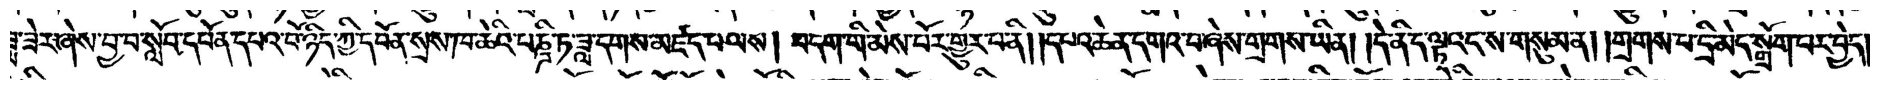

In [8]:
score_dict = {}

idx = 524
#00010029_163-310_263-310_263-340_163-340
sample_name = os.path.basename(eval_images[idx]).split(".")[0]

test_img = cv2.imread(eval_images[idx])
line_image = resize_to_height(test_img, target_height=60)

test_lbl = read_label(eval_labels[idx])
test_lbl = converter.toWylie(test_lbl)
test_lbl = process_wylie_label(test_lbl)

p_test_img = prepare_ocr_image2(line_image, target_height=ocr_inference._input_height)
img_batch = np.array(p_test_img)
img_batch = np.expand_dims(img_batch, axis=1)

predicted_text, raw = ocr_inference.run(img_batch, replace_tsheg=" ")
predicted_text = predicted_text[0].replace("/ ", "")
predicted_text = predicted_text.replace(" ", "§")
print(test_lbl)
print(predicted_text)

if len(predicted_text) > 0:
    cer_score = cer_scorer.compute(predictions=[predicted_text], references=[test_lbl])
    print(cer_score)
    cer_score = fastwer.score_sent(predicted_text, test_lbl, char_level=True)
    print(cer_score / len(predicted_text))

show_image(test_img)

In [14]:
cer_scores = {}

for image, label in tqdm(zip(eval_images, eval_labels), total=len(eval_images)):
    sample_name = os.path.basename(image).split(".")[0]
    test_img = cv2.imread(image)
    test_lbl = read_label(label)

    if test_lbl == "":
         print(f"empty label found: {sample_name}")
         continue
    
    #test_lbl = converter.toWylie(test_lbl)
    test_lbl = preprocess_wylie(test_lbl)
    test_lbl = process_wylie_label(test_lbl)

    test_img = prepare_ocr_image2(test_img, target_height=ocr_inference._input_height)
    np_img_batch = np.array(test_img)
    np_img_batch = np.expand_dims(np_img_batch, axis=1)

    predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
    predicted_text = predicted_text[0].replace("/ ", "")
    predicted_text = predicted_text.replace(" ", "§")

    if predicted_text == "":
         continue

    cer_score = cer_scorer.compute(predictions=[predicted_text], references=[test_lbl])
    cer_scores[sample_name] = (cer_score)

mean_cer = np.mean(cer_scores)

print(f"Mean CER: {mean_cer}")
print(f"Max CER: {max(cer_scores)}")
print(f"Min CER: {min(cer_scores)}")

with open(f"{eval_dataset}/cer_scores.txt", "w") as f:
    for idx, c_score in enumerate(cer_scores):
            f.write(f"{c_score}, {test_labels[idx]}\n")

 30%|██▉       | 8501/28628 [10:19<24:26, 13.73it/s]  


ValueError: one or more references are empty strings